<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P3_Language_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Language Models

A **language model** learns patterns in a sequence of tokens and predicts what is likely to come next.

For a sequence

$$
x_1, x_2, \ldots, x_T
$$

the probability of the whole sequence can be written as:

$$
P(x_1, x_2, \ldots, x_T)
=
\prod_{t=1}^{T}
P(x_t \mid x_1, \ldots, x_{t-1})
$$

This means that the model repeatedly asks:

> **Given the previous tokens, how likely is the next token?**

For example:

$$
P(\text{deep, learning, is, fun})
$$

can be written as:

$$
P(\text{deep})
\cdot
P(\text{learning}\mid\text{deep})
\cdot
P(\text{is}\mid\text{deep, learning})
\cdot
P(\text{fun}\mid\text{deep, learning, is})
$$

### Why This Matters for RNNs

To predict the next token, the model needs information from earlier tokens.

An RNN handles this using a **hidden state** that carries information forward through time:

$$
x_t + h_{t-1}
\rightarrow
h_t
\rightarrow
\text{next-token prediction}
$$

where:

- $x_t$ = current token
- $h_{t-1}$ = memory from previous time steps
- $h_t$ = updated memory

> **Key idea:** Language modeling gives us a practical task for an RNN: read a sequence one token at a time and use the hidden state to predict what comes next.

### A Simpler Approach: n-grams

A simple language model can look at only a small number of previous words.

- **Unigram:** uses no previous word
- **Bigram:** uses the previous 1 word
- **Trigram:** uses the previous 2 words

For example, a bigram model estimates:

$$
P(x_t \mid x_{t-1})
$$

instead of using the entire history.

> **Limitation:** n-gram models use only a fixed amount of context. RNNs are more flexible because they carry information forward through a hidden state.

## Evaluating a Language Model: Perplexity

After training a language model, we need a way to measure **how well it predicts the next token**.

A common evaluation metric for language models is **perplexity**.

Conceptually:

> **Perplexity measures how uncertain or "surprised" the model is when predicting the correct next token.**

- **Lower perplexity = better predictions**
- **Higher perplexity = more uncertainty**
- The best possible perplexity is **1**

Perplexity is calculated from the average negative log-probability of the correct tokens:

$$
\text{Perplexity}
=
\exp\left(
-\frac{1}{T}
\sum_{t=1}^{T}
\log P(x_t \mid x_1,\ldots,x_{t-1})
\right)
$$

where:

- $T$ = number of tokens
- $x_t$ = actual token at time step $t$
- $P(x_t \mid x_1,\ldots,x_{t-1})$ = probability the model assigns to the correct token

### Intuition

Suppose two RNN language models predict the same text:

- Model A: perplexity = **5**
- Model B: perplexity = **20**

Model A is better because it is **less uncertain about the correct next tokens**.

> **Key idea:** During training we want the RNN to assign high probability to the correct next token. As these predictions improve, the loss and perplexity decrease.

## Partitioning Sequences

Before training the RNN, we need to prepare the text as **input and target sequences**.

The RNN reads a sequence of characters and tries to predict the **next character** at each time step.

For example, suppose part of our text is:

`the time machine`

We can create:

**Input (X):**

`the time machin`

**Target (Y):**

`he time machine`

Notice that the target is the original sequence shifted by **one character**.

This gives the RNN the correct next character for every position:

| Current character | Correct next character |
|---|---|
| `t` | `h` |
| `h` | `e` |
| `e` | `space` |
| `space` | `t` |
| `t` | `i` |
| `i` | `m` |
| `m` | `e` |

During training, the RNN makes a prediction at each time step and compares it with the correct character in the target sequence.

> **Key idea:** The input tells the RNN what it sees now, and the target tells it what character should come next.

The long text is divided into many shorter sequences like this so that they can be used to train the RNN in minibatches.

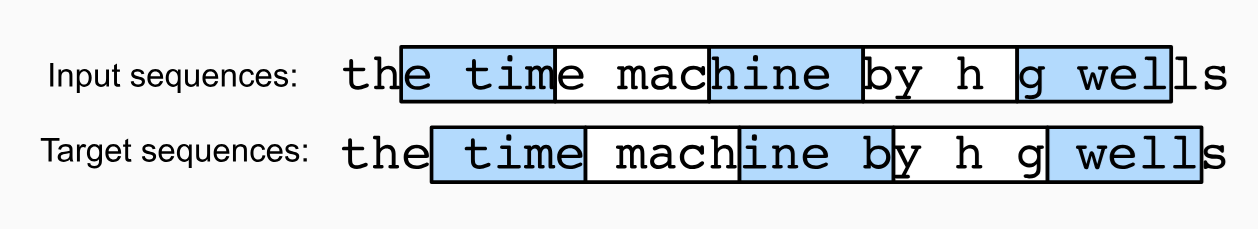

In [ ]:
# Example character sequence
sequence = list("time")

# Input sequence: all characters except the last one
X = sequence[:-1]

# Target sequence: all characters except the first one
# This shifts the sequence forward by one character
Y = sequence[1:]

print("Original:", sequence)
print("Input X: ", X)
print("Target Y:", Y)

Original: ['t', 'i', 'm', 'e']
Input X:  ['t', 'i', 'm']
Target Y: ['i', 'm', 'e']


In [ ]:
# Show the input-target pairs used for next-character prediction.
for x, y in zip(X, Y):
    print(f"{x} -> {y}")

t -> i
i -> m
m -> e


This is how we create the input X and target Y for next-token prediction. The target is simply the sequence shifted forward by one token.

In other words, to train our RNN for next-token prediction, we create input X and target Y by shifting the sequence forward by one token.

## Summary

Before introducing RNNs, we established the language-modeling task:

1. Text is converted into a sequence of **tokens**.
2. A language model learns to **predict the next token** from previous tokens.
3. For training, we create an **input sequence (X)** and a **target sequence (Y)**.
4. The target sequence is the input sequence shifted forward by **one token**.

For example:

    Original:  t  i  m  e
    X:         t  i  m
    Y:         i  m  e

So the training task is:

    t → i
    i → m
    m → e

The quality of a language model can be evaluated using **perplexity**.  
**Lower perplexity means better next-token prediction.**

> **Next step:** We now introduce RNNs, which use a hidden state to carry information from earlier time steps while processing a sequence.